In [79]:
from pyDashNetworkCode import *
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt

#gStore = GapJunctionGraph()
gStore = neuralNet()
app = graphApp(gStore,default_stylesheet)
app.app.run(mode='inline', port=8054,debug=True)
# app = createIonChannelApp(gStore,default_stylesheet)
#saving a graph after you removed nodes doesnt really work
#i think the edges dont get updated 


In [80]:
from auxillaryFunctions import *
np.random.seed(0)
STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
STNbias = -2.5
TS = 0.05  
delay = TS
nNeurons = len(gStore.G.nodes)

STNDendriteMap = []
STNDendriteInfo = []
STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias) for i in range(nNeurons)]
neuronDict = {"STN":STNNeurons}
baseConductance = 0.02
synapses = {"exc":genAMPA(TS,baseConductance,conductanceGain=0),
                # "NMDA":genNMDA(TS,baseConductance,conductanceGain=0),
                "inh":genGABA(TS,0.2,conductanceGain=0)}

synapseData = []
for key, val in gStore.G.edges.items():
    e0,e1 = key
    synapseType = val["synapseType"]
    cond = ast.literal_eval(val["conductance"])
    synapseInfo = deepcopy(synapses[synapseType])
    synapseInfo["conductance"] = cond*synapseInfo["conductance"] 
    preName = "STN" #gStore.G.nodes[e0]["label"]
    postName = "STN" #gStore.G.nodes[e1]["label"]
    synDat = {"pre":e0,"post":e1,"synapse":deepcopy(synapseInfo),
              "delay":delay,"preName":preName,"postName":postName,"segmentIndex":0}
    synapseData.append(synDat)

synapseDict = {"all":synapseData}
simData,connectionToChannelMap = genSimData(neuronDict,{},synapseDict,TS)
print(f"Total number of channels {simData['nChannels']}")

Total number of channels 25


In [66]:
#NOTE: October 22: New problem when synapses are introduced. Vectorized sim is unstable, need to figure out why
#October 31: problem seems to be when there are more than 1 synapses. Spike timings are wrong? 

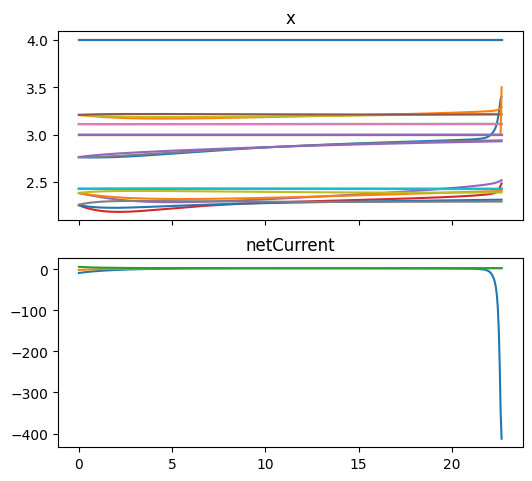

In [124]:
stimInfoSpikes = {}
syns = [i for i,n in enumerate(simData["name"]) if n == "AMPAR"] #"AMPAR" #GABA
#stimSynapse(stimInfoSpikes,syns,50,100,TS)

runTime = 22.655
stimInfoCurrents = {} 
# stimBiasCurrent(stimInfoCurrents,segmentsToStim=[0],currentValue=3.0,startTime=100,stopTime=115,TS=TS)

simDataPy = deepcopy(simData)
simDataPy["debugRecording"] = np.zeros_like(simDataPy["current"])
data = solveSystemStandard(simDataPy,TS,runTime,stimInfoSpikes,stimInfoCurrents,vectorized=False,
                           recordingKeys = ["voltages","calciumVals","netCurrent","x","debugRecording","CaChannelCurrent"])

keysToPlot = ["x","netCurrent","time",]
standardPlot({key:data[key] for key in keysToPlot})
#plt.plot(data["time"],data["debugRecording"][:,synapsesToStim])

In [125]:
def calcWeightChangeVectorized(ac,TS):
    rate,gammaP,gammaD,thetaP,thetaD = ac["rate"],ac["gammaP"],ac["gammaD"],ac["thetaP"],ac["thetaD"]
    p = ac["efficacy"]
    Ca = ac["calciumVals"][ac["postNeuron"]]
    #from the Graupner and Brunel paper
    #rate = 1/tau 
    pStar = 0.5
    revP = (1.0-p)
    fp = -p*revP*(pStar-p)
    potentiation = gammaP*revP*(Ca>thetaP)
    depression = -gammaD*p*(thetaD<Ca)*(Ca<=thetaP)
    Noise = 0
    dp = rate*fp+potentiation+depression+Noise
    ac["efficacy"]+=TS*dp

def fastChannelUpdate(ac,TS,spikeOverwriteList):
    xs = ac["x"].flatten()
    xhs,xks = ac["vHalf"].flatten(),ac["vKi"].flatten()
    xts0,xts1 = ac["tau0"].flatten(),ac["tau1"].flatten()
    xths,xtks = ac["th"].flatten(),ac["tkInv"].flatten()
    V = ac["voltages"][ac["postNeuron"]]
    minOpenness = ac["minOpenness"].flatten()
    Ca = ac["calciumVals"][ac["postNeuron"]]

    #spikeOverwriteList = np.zeros(ac["nChannels"])

    synapseDelay = ac["inputDelay"]
    readIndex = ((ac["writeIndex"][ac["channelPreSpiker"]]-synapseDelay)%ac["maxDelayInt"])
    perceivedSpike = ac["spikeBuffer"][ac["channelPreSpiker"]][readIndex].T
    perceivedSpike = np.maximum(spikeOverwriteList,perceivedSpike)[0]

    inputs = np.stack([V,V,Ca,perceivedSpike],-1,dtype=np.float32).flatten()
    res = solveGate(xs,inputs,TS,xhs,xks,xts0,xts1,xths,xtks,minOpenness)
    ac["x"] = res.reshape([-1,4])

def updateCurrents(ac):
    xs = ac["x"]
    exponents = ac["exponent"]

    gatingTotal = np.prod(xs ** exponents, axis=1)

    V = ac["voltages"][ac["postNeuron"]]
    Erev = ac["Erev"]
    g0 = ac["conductance"]
    p = ac["efficacy"]
    w = ac["conductanceGain"]
    CaCurrent = ac["CaCurrent"]

    g = g0 + w*p
    I = g*gatingTotal*(V-Erev) 
    ac["current"] = I
    ac["CaChannelCurrent"] = CaCurrent*I 
    ac["debugRecording"] = gatingTotal

def solveSystemStandard(ac,TS,runTime,stimInfoSpikes={},stimInfoCurrents= {},vectorized=False,
                        recordingKeys = ["voltages","calciumVals","netCurrent","current","spikeBuffer"]):
    nIterations = int(runTime/TS)
    ##Spike stim
    spikeStimTimes,spikeStimNeurons = genSpikeStimArrays(stimInfoSpikes)
    maxSpikeStimInd = len(spikeStimTimes)    
    spikeStimArrayIter = 0

    ##intracellular bias current stimulation
    biasStimTimes,biasStimSegments,biasStimValues = genBiasStimArrays(stimInfoCurrents)
    maxBiasStimInd = len(biasStimTimes)
    biasStimArrayIter = 0
    
    data = {key:[] for key in recordingKeys}
    tv = np.linspace(0,runTime,nIterations)
    nNeurons = ac["nNeurons"]
    nChannels = ac["nChannels"]
    
    for iteration,t in enumerate(tv):
        #calculate currents
        ac["netCurrent"] = np.zeros([nNeurons])
        ac["netCaCurrent"] = np.zeros([nNeurons])
        spikeOverwriteList = np.zeros(nChannels,dtype=np.float32)
        biasOverWriteList = np.zeros(nNeurons,dtype=np.float32)

        while spikeStimArrayIter<maxSpikeStimInd and iteration == spikeStimTimes[spikeStimArrayIter]:
            syn = spikeStimNeurons[spikeStimArrayIter]
            spikeOverwriteList[syn] = 1
            spikeStimArrayIter +=1

        while biasStimArrayIter<maxBiasStimInd and iteration == biasStimTimes[biasStimArrayIter]:
            seg = biasStimSegments[biasStimArrayIter]
            val = biasStimValues[biasStimArrayIter]
            biasOverWriteList[seg] = val
            biasStimArrayIter +=1

        #update the gates
        #solveChannels(ac,spikeOverwriteList,TS)
        if vectorized:
            updateCurrents(ac)
            fastChannelUpdate(ac,TS,spikeOverwriteList)
            calcWeightChangeVectorized(ac,TS)
        else:
            solveChannels(ac,spikeOverwriteList,TS)


        solveDiffusiveConnections(ac)

        #Accumulate current
        np.add.at(ac["netCurrent"],ac["postNeuron"],ac["current"])
        np.add.at(ac["netCaCurrent"],ac["postNeuron"],ac["CaChannelCurrent"])

        solveNeurons(ac,biasOverWriteList,TS)

        solveSpikers(ac)

        for key in data:
            data[key].append(deepcopy(ac[key]))

    for key in data:
        data[key] = np.array(data[key])
    data["time"] = tv
    return data

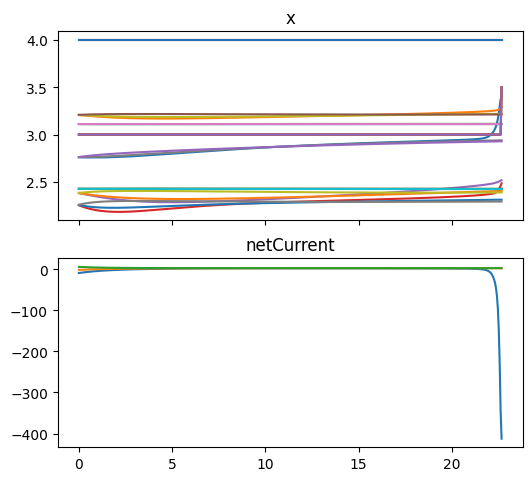

In [126]:
simDataPy2 = deepcopy(simData)
simDataPy2["debugRecording"] = np.zeros_like(simDataPy["current"])
data2 = solveSystemStandard(simDataPy2,TS,runTime,stimInfoSpikes,stimInfoCurrents,vectorized=True,
                           recordingKeys = ["voltages","calciumVals","netCurrent","x","debugRecording","CaChannelCurrent"])
standardPlot({key:data2[key] for key in keysToPlot})

In [128]:
simDataPy2["spikeBuffer"]

array([[ True],
       [False],
       [False]])

In [129]:
simDataPy["spikeBuffer"]

array([[ True],
       [False],
       [False]])

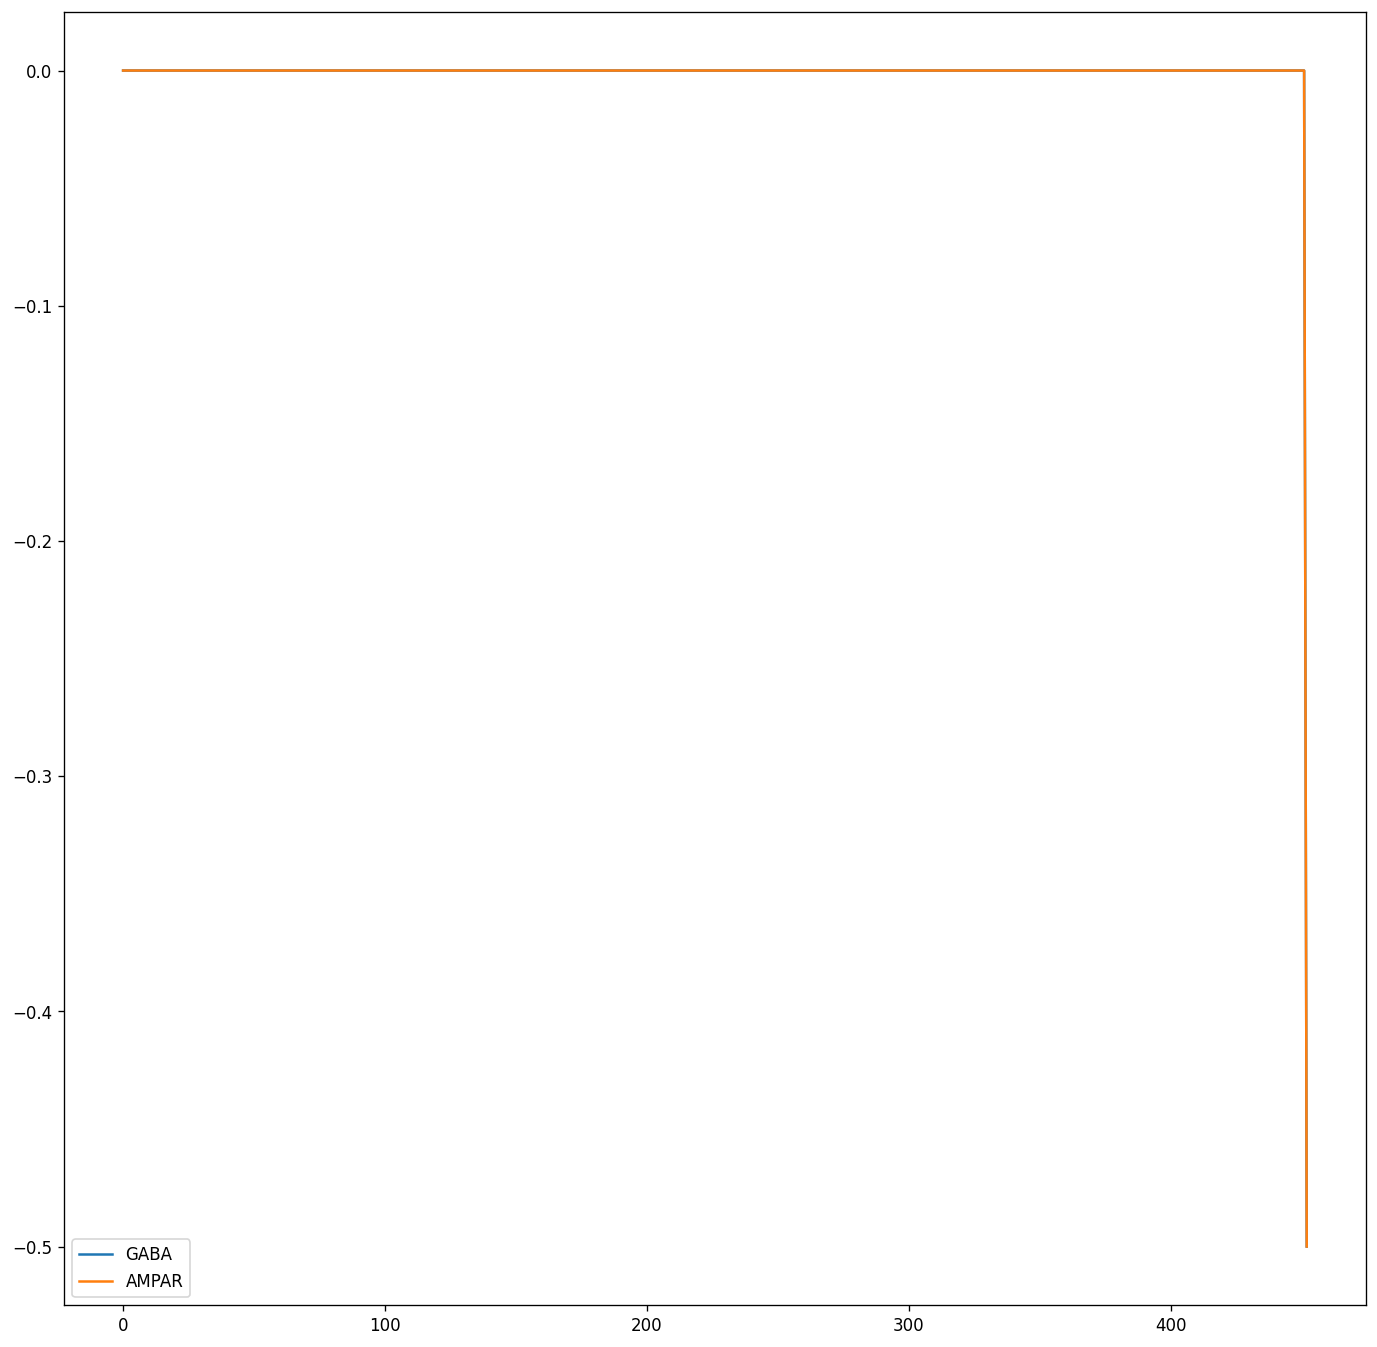

In [132]:
y = data["x"] - data2["x"]
names = simDataPy2["name"]

plt.figure(figsize=(14,14),dpi=120)
plt.plot(y.sum(axis=2)[:,-2::],label=names[-2::]);
plt.legend();

In [138]:
ac = simDataPy2
synapseDelay = ac["inputDelay"]
readIndex = ((ac["writeIndex"][ac["channelPreSpiker"]]-synapseDelay)%ac["maxDelayInt"])
perceivedSpike = ac["spikeBuffer"][ac["channelPreSpiker"]][readIndex].T
perceivedSpike

array([[ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True]])

In [140]:
ac = simDataPy
spikes = []
readIndices = []
for i in range(ac["nChannels"]):
    preSynapticSpiker = ac["channelPreSpiker"][i] 
    nChannels = ac["nChannels"]
    voltage = ac["voltages"]
    calciumVals = ac["calciumVals"]
    writeIndex = ac["writeIndex"]
    maxDelay = ac["maxDelayInt"]
    synapseDelay = ac["inputDelay"][i]
    readIndex = int((writeIndex[preSynapticSpiker]-synapseDelay)%maxDelay)
    readIndices.append(readIndex)
    perceivedSpike = ac["spikeBuffer"][preSynapticSpiker][readIndex]
    #perceivedSpike = max(perceivedSpike,spikeOverwriteList[i])
    spikes.append(bool(perceivedSpike))

print(spikes)
print(readIndexreadIndexs)

[True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, False, False, False]


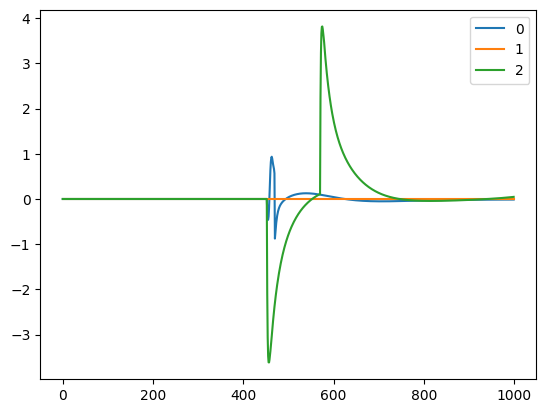

In [8]:
key = "netCurrent"
x =data[key]-data2[key]
plt.plot(x,label=[str(i) for i in range(len(x[0]))])
plt.legend()

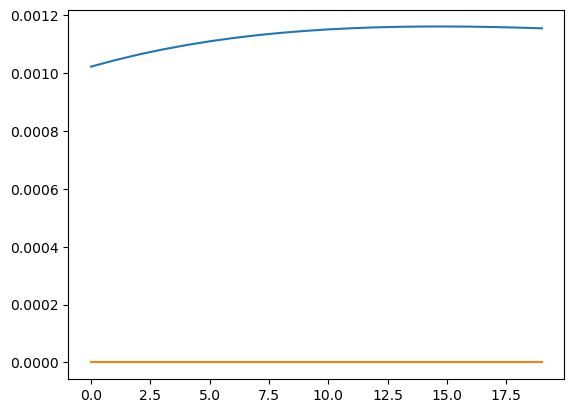

In [97]:
plt.plot(data[key][0:20,4])
plt.plot(data2[key][0:20,4])

In [ ]:
#
a = data["voltages"]-data2["voltages"]
plt.plot(a.T[0])

In [90]:
def sigmoid(z,h,kInv,minOp):
    return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))

def solveGate(x,s,TS,xh,xk,xt0,xt1,xth,xtk,minOpenness):
    xInf = sigmoid(s,xh,xk,minOpenness)#*(xt0+xt1)/TS
    tau = xt0 + xt1*sigmoid(s,xth,xtk,0)
    #return x + TS*(xInf-x)/tau
    return (tau*x + TS*xInf)/(tau+TS)



def fastChannelUpdate(ac,TS,spikeOverwriteList):
    xs = ac["x"].flatten()
    xhs,xks = ac["vHalf"].flatten(),ac["vKi"].flatten()
    xts0,xts1 = ac["tau0"].flatten(),ac["tau1"].flatten()
    xths,xtks = ac["th"].flatten(),ac["tkInv"].flatten()
    V = ac["voltages"][ac["postNeuron"]]
    minOpenness = ac["minOpenness"].flatten()
    Ca = ac["calciumVals"][ac["postNeuron"]]

    #spikeOverwriteList = np.zeros(ac["nChannels"])

    synapseDelay = ac["inputDelay"][i]
    readIndex = ((ac["writeIndex"][ac["channelPreSpiker"]]-synapseDelay)%ac["maxDelayInt"])
    perceivedSpike = ac["spikeBuffer"][ac["channelPreSpiker"]][readIndex].T
    perceivedSpike = np.maximum(spikeOverwriteList,perceivedSpike)[0]

    inputs = np.stack([V,V,Ca,perceivedSpike],-1).flatten()
    res = solveGate(xs,inputs,TS,xhs,xks,xts0,xts1,xths,xtks,minOpenness)
    ac["x"] = res.reshape([-1,4])

def updateCurrents(ac):
    exponents = ac["exponent"].flatten()
    xs = ac["x"].flatten()
    scaled = xs*exponents
    gatingTotal = np.ones(ac["nChannels"])
    np.multiply.at(gatingTotal,np.repeat(np.arange(ac["nChannels"]),4),scaled)

    V = ac["voltages"][ac["postNeuron"]]
    minOpenness = ac["minOpenness"]
    Erev = ac["Erev"]
    g0 = ac["conductance"]
    p = ac["efficacy"]
    w = ac["conductanceGain"]
    CaCurrent = ac["CaCurrent"]

    g = g0 + w*p
    I = g*gatingTotal*(V-Erev) 
    ac["current"] = I
    ac["CaChannelCurrent"] = CaCurrent*I 

ac = simDataPy

In [114]:
def calcWeightChange(p,Ca,rate,gammaP,gammaD,thetaP,thetaD):
    #from the Graupner and Brunel paper
    #rate = 1/tau 
    pStar = 0.5
    revP = (1.0-p)
    fp = -p*revP*(pStar-p)
    potentiation = gammaP*revP*(Ca>thetaP)
    depression = -gammaD*p*(thetaD<Ca)*(Ca<=thetaP)
    Noise = 0
    return rate*fp+potentiation+depression+Noise

p = ac["efficacy"]
Ca = ac["calciumVals"][ac["postNeuron"]]
dp = calcWeightChange(p,Ca,ac["rate"],ac["gammaP"],ac["gammaD"],ac["thetaP"],ac["thetaD"])
ac["efficacy"]+=TS*dp

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)

In [116]:
def calcWeightChangeVectorized(ac,TS):
    rate,gammaP,gammaD,thetaP,thetaD = ac["rate"],ac["gammaP"],ac["gammaD"],ac["thetaP"],ac["thetaD"]
    p = ac["efficacy"]
    Ca = ac["calciumVals"][ac["postNeuron"]]
    #from the Graupner and Brunel paper
    #rate = 1/tau 
    pStar = 0.5
    revP = (1.0-p)
    fp = -p*revP*(pStar-p)
    potentiation = gammaP*revP*(Ca>thetaP)
    depression = -gammaD*p*(thetaD<Ca)*(Ca<=thetaP)
    Noise = 0
    dp = rate*fp+potentiation+depression+Noise
    ac["efficacy"]+=TS*dp

calcWeightChangeVectorized(ac,TS)


In [74]:
perceivedSpike

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [ ]:
readIndex = int((writeIndex[ac["channelPreSpiker"]]-synapseDelay)%ac["maxDelayInt"])
perceivedSpike = ac["spikeBuffer"][ac["channelPreSpiker"]][readIndex]
perceivedSpike = max(perceivedSpike,spikeOverwriteList[i])

In [45]:
ac["x"].flatten()

array([1.17894016e-01, 8.38222504e-01, 1.00000000e+00, 1.00000000e+00,
       2.43112355e-01, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.12185284e-01, 1.00000000e+00,
       3.24623585e-01, 1.93082467e-02, 1.00000000e+00, 1.00000000e+00,
       4.58773106e-01, 9.04160459e-03, 1.00000000e+00, 1.00000000e+00,
       1.30005684e-02, 4.58220869e-01, 9.91892159e-01, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       9.73109305e-02, 8.37145627e-01, 1.00000000e+00, 1.00000000e+00,
       2.25938037e-01, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.11554459e-01, 1.00000000e+00,
       2.96726376e-01, 1.97915062e-02, 1.00000000e+00, 1.00000000e+00,
       4.11975086e-01, 9.07758065e-03, 1.00000000e+00, 1.00000000e+00,
       1.39367860e-02, 4.53818083e-01, 9.91888642e-01, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
      

In [ ]:
tempTS = TS
gatingTotal = 1

for j in range(len(xs)):
    x = xs[j]
    n = exponents[j]
    gatingTotal *= (x**n)
